# Inference and visualisation

Runs a trained model on one CubiCasa5k test image, the same way the API does (`Detector` from `run.py`), and draws
its boxes next to the ground truth. This notebook made `examples/prediction_example.png`.

It expects the weights in `weights/`, the COCO annotations in `data/cubicasa5k_coco/` and the CubiCasa5k images in
`data/CubiCasa5k/data/cubicasa5k/` (see the README). Run it from the `notebooks/` directory.

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt

REPO = Path('..')
sys.path.insert(0, str(REPO))
from run import CONFIG_DIR, MODELS, Detector  # noqa: E402

MODEL = 'cascade_swin'
CHECKPOINT = REPO / 'weights' / f'{MODEL}_latest.pth'
ANNOTATIONS = REPO / 'data' / 'cubicasa5k_coco' / 'test_coco_pt.json'
IMAGE_ROOT = REPO / 'data' / 'CubiCasa5k' / 'data' / 'cubicasa5k'
IMAGE = 'high_quality_architectural/1191/F1_original.png'  # an image from the test split
SCORE_THRESHOLD = 0.3
COLORS = {'wall': '#1f4fd1', 'room': '#e8590c'}

In [2]:
detector = Detector(CONFIG_DIR / MODELS[MODEL], CHECKPOINT, device='cpu', score_threshold=SCORE_THRESHOLD)

Loads checkpoint by local backend from path: ../weights/cascade_swin_latest.pth


Ground truth boxes for the image. The annotation files store absolute Kaggle paths, so the image is matched by the
end of its path.

In [3]:
coco = json.loads(ANNOTATIONS.read_text())
image_info = next(im for im in coco['images'] if im['file_name'].endswith('/' + IMAGE))
categories = {c['id']: c['name'] for c in coco['categories']}
ground_truth = [(categories[a['category_id']], a['bbox'])
                for a in coco['annotations'] if a['image_id'] == image_info['id']]

image = cv2.imread(str(IMAGE_ROOT / IMAGE))  # BGR, as the API receives it after decoding
response = detector.predict(image)
predictions = [
    (name, [d.position.start.x, d.position.start.y,
            d.position.end.x - d.position.start.x, d.position.end.y - d.position.start.y])
    for name, detections in (('wall', response.detectionResults.walls), ('room', response.detectionResults.rooms))
    for d in detections
]
print(f'{len(ground_truth)} ground truth boxes, {len(predictions)} predicted boxes, '
      f'mean confidence {response.confidence:.3f}')

64 ground truth boxes, 46 predicted boxes, mean confidence 0.732


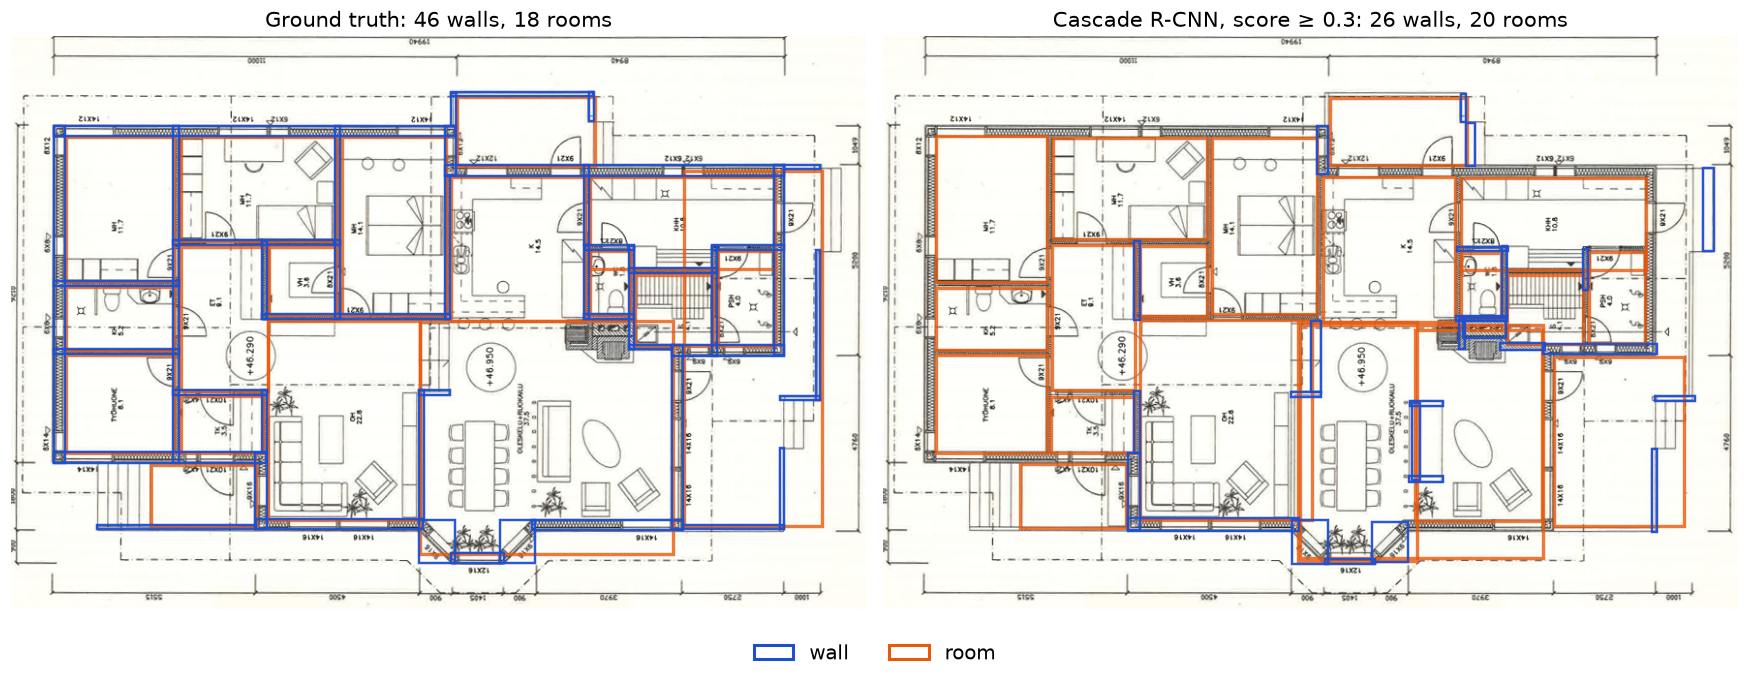

In [4]:
def draw(ax, title, boxes):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    # Rooms first, walls on top: wall boxes are thin and would hide under room outlines.
    for name, (x, y, w, h) in sorted(boxes, key=lambda box: box[0] == 'wall'):
        ax.add_patch(patches.Rectangle((x, y), w, h, facecolor='none', edgecolor=COLORS[name],
                                       linewidth=1.6 if name == 'wall' else 2.2,
                                       alpha=0.95 if name == 'wall' else 0.8))
    walls = sum(name == 'wall' for name, _ in boxes)
    ax.set_title(f'{title}: {walls} walls, {len(boxes) - walls} rooms', fontsize=14)
    ax.axis('off')


height, width = image.shape[:2]
fig, axes = plt.subplots(1, 2, figsize=(16, 16 * height / (2 * width) + 0.9), dpi=110)
draw(axes[0], 'Ground truth', ground_truth)
draw(axes[1], f'Cascade R-CNN, score ≥ {SCORE_THRESHOLD}', predictions)
legend = [patches.Patch(edgecolor=c, facecolor='none', linewidth=2, label=n) for n, c in COLORS.items()]
fig.legend(handles=legend, loc='lower center', ncol=2, frameon=False, fontsize=13)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(REPO / 'examples' / 'prediction_example.png', facecolor='white')
plt.show()